# CodeAlpha Data Analytics Internship

## Task 2: Exploratory Data Analysis (EDA)

### Project: Item and Category Analysis

This project performs Exploratory Data Analysis on an item-category dataset.

The analysis focuses on:
- Dataset structure
- Data quality
- Item uniqueness
- Category distribution
- Category-wise item counts
- Data visualization
- Key insights

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("supermarket_sales.csv")

In [ ]:
df.head()

,Item Code,Item Name,Category Code,Category Name
0,102900005115168,Niushou Shengcai,1011010101,Flower/Leaf Vegetables
1,102900005115199,Sichuan Red Cedar,1011010101,Flower/Leaf Vegetables
2,102900005115625,Local Xiaomao Cabbage,1011010101,Flower/Leaf Vegetables
3,102900005115748,White Caitai,1011010101,Flower/Leaf Vegetables
4,102900005115762,Amaranth,1011010101,Flower/Leaf Vegetables


In [ ]:
df.tail()

,Item Code,Item Name,Category Code,Category Name
246,106958851400125,Haixian Mushroom (Bag) (4),1011010801,Edible Mushroom
247,106971533450003,Haixian Mushroom (Bunch),1011010801,Edible Mushroom
248,106971533455008,Haixian Mushroom (Bag) (3),1011010801,Edible Mushroom
249,106973223300667,Chinese Caterpillar Fungus Flowers (Box) (2),1011010801,Edible Mushroom
250,106973990980123,Hfyg Haixian Mushroom (Bunch),1011010801,Edible Mushroom


In [ ]:
df.columns

Index(['Item Code', 'Item Name', 'Category Code', 'Category Name'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Item Code      251 non-null    int64 
 1   Item Name      251 non-null    object
 2   Category Code  251 non-null    int64 
 3   Category Name  251 non-null    object
dtypes: int64(2), object(2)
memory usage: 8.0+ KB


In [ ]:
df.dtypes

,0
Item Code,int64
Item Name,object
Category Code,int64
Category Name,object


In [ ]:
df.describe()

,Item Code,Category Code
count,2.510000e+02,2.510000e+02
mean,1.031908e+14,1.011010e+09
std,1.048400e+12,2.915469e+02
min,1.029000e+14,1.011010e+09
25%,1.029000e+14,1.011010e+09
50%,1.029000e+14,1.011011e+09
75%,1.029000e+14,1.011011e+09
max,1.069740e+14,1.011011e+09


In [ ]:
df.isnull().sum()

,0
Item Code,0
Item Name,0
Category Code,0
Category Name,0


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
Item Code,0.0
Item Name,0.0
Category Code,0.0
Category Name,0.0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()]

,Item Code,Item Name,Category Code,Category Name


In [ ]:
df["Item Code"].nunique()

251

In [ ]:
df["Item Name"].nunique()

247

In [ ]:
df["Category Name"].nunique()

6

In [ ]:
df["Category Code"].nunique()

6

In [ ]:
category_counts = df["Category Name"].value_counts()

category_counts

,count
Category Name,
Flower/Leaf Vegetables,100
Edible Mushroom,72
Capsicum,45
Aquatic Tuberous Vegetables,19
Solanum,10
Cabbage,5


In [ ]:
category_percentage = (
    df["Category Name"]
    .value_counts(normalize=True) * 100
)

category_percentage

,proportion
Category Name,
Flower/Leaf Vegetables,39.840637
Edible Mushroom,28.685259
Capsicum,17.928287
Aquatic Tuberous Vegetables,7.569721
Solanum,3.984064
Cabbage,1.992032


In [ ]:
category_summary = (
    df["Category Name"]
    .value_counts()
    .rename_axis("Category Name")
    .reset_index(name="Item Count")
)

category_summary["Percentage"] = (
    category_summary["Item Count"] / len(df) * 100
)

category_summary

,Category Name,Item Count,Percentage
0,Flower/Leaf Vegetables,100,39.840637
1,Edible Mushroom,72,28.685259
2,Capsicum,45,17.928287
3,Aquatic Tuberous Vegetables,19,7.569721
4,Solanum,10,3.984064
5,Cabbage,5,1.992032


In [ ]:
largest_category = df["Category Name"].value_counts().idxmax()
largest_category

'Flower/Leaf\xa0Vegetables'

In [ ]:
smallest_category = df["Category Name"].value_counts().idxmin()
smallest_category

'Cabbage'

In [ ]:
df.groupby("Category Name")["Category Code"].nunique()

,Category Code
Category Name,
Aquatic Tuberous Vegetables,1
Cabbage,1
Capsicum,1
Edible Mushroom,1
Flower/Leaf Vegetables,1
Solanum,1


In [ ]:
df["Item Code"].nunique()

251

In [ ]:
len(df)

251

In [ ]:
df["Item Name"].duplicated().sum()

np.int64(4)

In [ ]:
df["Item Name"].nunique()

247

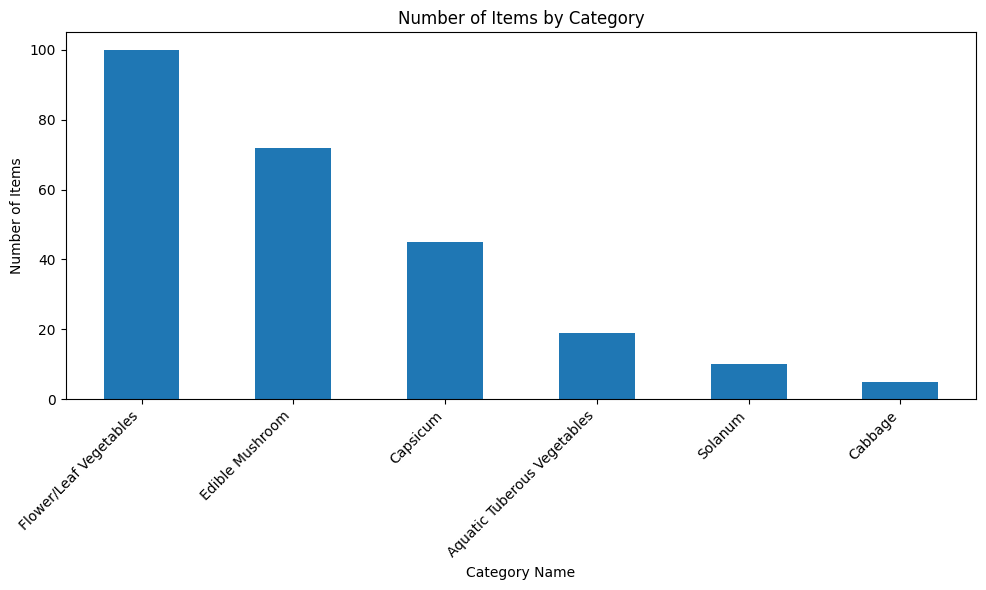

In [ ]:
category_counts = df["Category Name"].value_counts()

plt.figure(figsize=(10, 6))

category_counts.plot(kind="bar")

plt.title("Number of Items by Category")
plt.xlabel("Category Name")
plt.ylabel("Number of Items")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

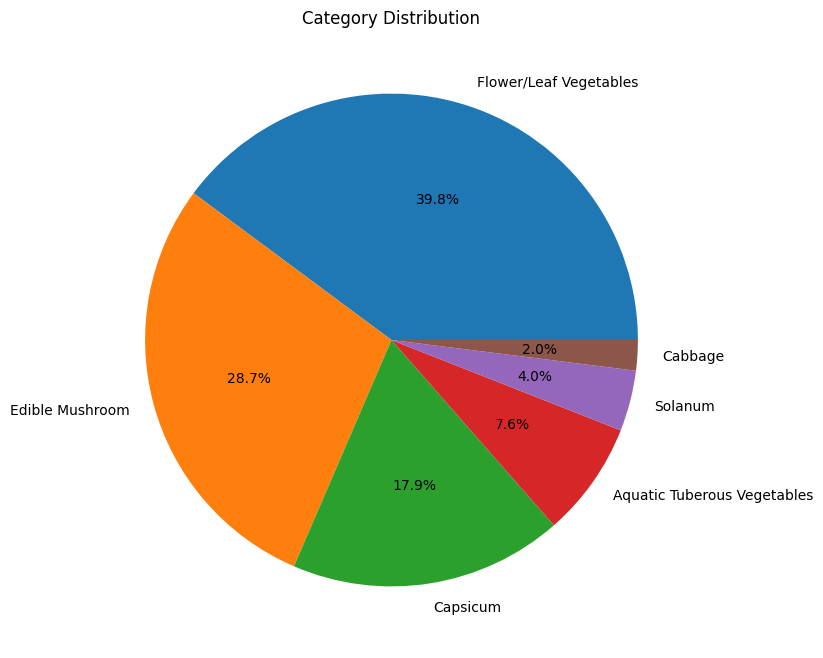

In [ ]:
plt.figure(figsize=(8, 8))

category_counts.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Category Distribution")
plt.ylabel("")

plt.show()

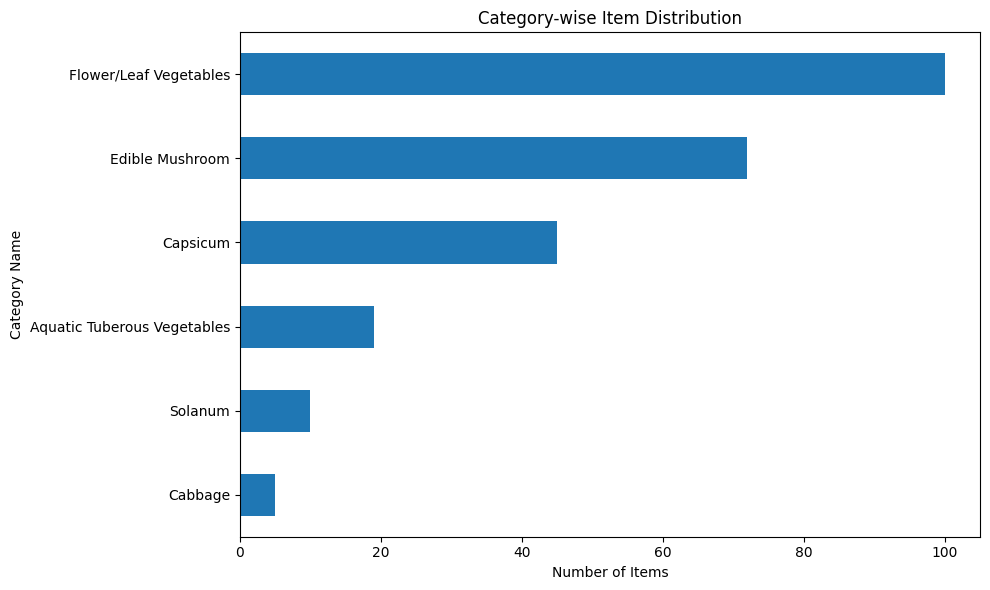

In [ ]:
plt.figure(figsize=(10, 6))

category_counts.sort_values().plot(kind="barh")

plt.title("Category-wise Item Distribution")
plt.xlabel("Number of Items")
plt.ylabel("Category Name")

plt.tight_layout()
plt.show()

## Key Findings

- The dataset contains 251 records.
- The dataset contains 6 different item categories.
- Flower/Leaf Vegetables is the largest category.
- Cabbage is the smallest category.
- Edible Mushroom is the second-largest category.
- The category distribution shows that Flower/Leaf Vegetables and Edible Mushroom represent a major portion of the dataset.
- Item codes and category codes were analyzed for uniqueness and consistency.
- Missing values and duplicate records were checked as part of data quality analysis.

## Conclusion

The Exploratory Data Analysis provided an overview of the item and category structure of the dataset. The analysis included dataset inspection, missing-value checking, duplicate detection, uniqueness analysis, category-wise distribution, and visualization.

The results show that Flower/Leaf Vegetables has the highest number of items, while Cabbage has the lowest. Bar charts and pie charts were used to clearly visualize the distribution of items across categories.

Overall, the dataset was successfully analyzed to identify its structure, data quality, category distribution, and important patterns.